# 01 · Fetch from OpenAlex

Fetches the 174 v1 query papers and every reference they list, by OpenAlex id, and normalizes each one with `src.openalex.normalize_work`.

Why this replaces v1's fetch/preprocess:
- **One record per id.** v1 looked references up by DataFrame index *label* as if it were a *position* (audit F6), so positives carried other papers' text. Here every paper is a dict keyed by its own id.
- **Same normalizer everywhere.** Queries, positives and negatives all go through `normalize_work`, so they have identical fields (audit F4).

Raw works are cached in `data/v2/openalex_works.jsonl` (gitignored). Re-running only fetches missing ids.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
from src.pipeline_v2 import fetch_all

queries, papers, missing = fetch_all()
n_refs = len({r for q in queries for r in q["referenced_works"]})
print(f"queries: {len(queries)}  |  unique references listed: {n_refs}")
print(f"fetched: {len(papers)}  |  not in OpenAlex anymore (404): {len(missing)}")
assert all(pid == rec["id"] for pid, rec in papers.items())

queries: 174  |  unique references listed: 1729
fetched: 1733  |  not in OpenAlex anymore (404): 155


### Query papers

In [3]:
q = pd.DataFrame([papers[x["id"]] for x in queries])
q["year"] = q["publication_date"].str[:4]
display(q["year"].value_counts().sort_index().rename("queries by year").to_frame().T)
print("queries without abstract:", (q["abstract"] == "").sum())

year,2020,2021,2022,2023,2024
queries by year,103,42,18,9,2


queries without abstract: 5


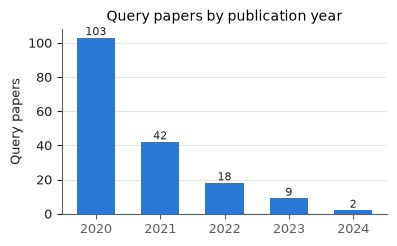

In [4]:
from src.figures import fig_query_years
save(fig_query_years(q["year"]), "01_query_years")

**Figure (01_query_years).** Publication year of the 174 query papers, according to OpenAlex. All come from v1's 2020+ corpus, which matters for the contamination check in `06_analysis`.

### References

A reference is usable only with a title **and** an abstract. v2 applies the same rule to positives and negatives; v1 required an abstract only for negatives.

In [5]:
query_ids = {x["id"] for x in queries}
refs = pd.DataFrame([papers[r] for r in {r for x in queries for r in x["referenced_works"]} if r in papers])
refs["has_abstract"] = refs["abstract"] != ""
refs["has_concepts"] = refs["concepts_array"].str.len() > 0
display(refs[["has_abstract", "has_concepts"]].mean().round(3).to_frame("share").T)
display(refs["publication_date"].str[:4].astype(int).describe().round(1).to_frame("reference year").T)

,has_abstract,has_concepts
share,0.77,1.0


,count,mean,std,min,25%,50%,75%,max
reference year,1574.0,2015.0,9.5,1882.0,2014.0,2018.0,2020.0,2023.0


### One normalized record

In [6]:
rec = papers[queries[0]["id"]]
{k: (v[:120] + "…" if isinstance(v, str) and len(v) > 120 else v[:5] if isinstance(v, list) else v)
 for k, v in rec.items()}

{'id': 'https://openalex.org/W4399940463',
 'title': 'ADMET-AI: a machine learning ADMET platform for evaluation of large-scale chemical libraries',
 'abstract': 'MOTIVATION: The emergence of large chemical repositories and combinatorial chemical spaces, coupled with high-throughput…',
 'concepts_array': ['Python (programming language)',
  'Computer science',
  'Web site',
  'Web server',
  'Drug discovery'],
 'publication_date': '2024-06-21',
 'author_ids': ['https://openalex.org/A5005590626',
  'https://openalex.org/A5005779176',
  'https://openalex.org/A5047561254',
  'https://openalex.org/A5054177213',
  'https://openalex.org/A5076940737'],
 'language': 'en',
 'type': 'article',
 'referenced_works': ['https://openalex.org/W2009867031',
  'https://openalex.org/W2593436234',
  'https://openalex.org/W2767891136',
  'https://openalex.org/W2775175656',
  'https://openalex.org/W2966357564']}

### Findings

- **Coverage.** All 174 v1 query papers were found in OpenAlex. Of 1,729 unique references they list, 155 have since been deleted from OpenAlex (HTTP 404) and are lost.
- **Recency.** Queries are recent (2020–2024; 103 from 2020). References are older (median year 2018, inter-quartile range 2014–2020).
- **Abstracts.** 77% of references have an abstract. Because v2 requires title + abstract for *every* candidate, the other 23% cannot be positives. v1 applied this requirement only to negatives, another asymmetry between the two groups.
- **Concepts.** Every fetched work carries OpenAlex concept tags, so concept presence can no longer separate positives from negatives (audit F4).